### Summary
Given data $\{(x_i, y_i)\}_{i=1}^n$ in a cluster, we fit the following model:
$$\hat{f}(x) = \frac{1}{2} (x-\mu)^\top H (x-\mu) + w^\top (x-\mu) + b$$
for some __triangular__ or __symmetric__ matrix $H$, vector $w$ and scalar $b$. If $x\in\mathbb{R}^d$, then we are fitting $D := d(d+1)/2 + d + 1 = \frac{1}{2}d^2 + \frac{3}{2}d + 1$ parameters. Note that the model above can be reformulated in terms of dot products as
$$\hat{f}(x) = \sum_{i\leq j}^d \frac{1}{2}H_{ij}x_ix_j + \sum_{i=1}^d w_i x_i + b.$$
As a dot product, let $\theta\in\mathbb{R}^D$ be the vector of parameters in the model:
$$\theta = \begin{bmatrix}H_{11} & H_{12} & \ldots & H_{dd} & w_1 & \ldots & w_d & b\end{bmatrix}$$
Then consider the modified row $\tilde{x} \in \mathbb{R}^d$ for a given data point:
$$\tilde{x} = \begin{bmatrix}x_1^2/2 & x_1x_2/2 & x_1x_3/2 & \ldots x_{d}x_{d-1}/2 & x_d^2/2 & x_1 & \ldots & x_d & 1 \end{bmatrix}.$$
Then $\hat{f}(x) = \theta \cdot \tilde{x}$. Then we want to solve the least squares problem $\min_\theta \|Y - X\theta\|_2^2$, where $X$ contains $\tilde{x}$ as its rows. The following code constructs $X$ and solves the least squares problem.

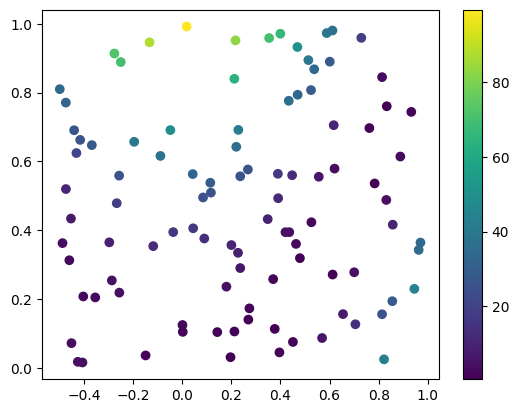

In [7]:
### Setup data
import matplotlib.pyplot as plt
import numpy as np
from src.problems.rosenbrock import rosenbrock, rosenbrock_hess

# Generate data
N = 100
d = 2 # for visualization
lx = -0.5;  ly = 0.0
rx = 1.0;   ry = 1.0
x = np.random.uniform([lx, ly], [rx, ry], (N, d))
Y = rosenbrock(x).flatten()

# Plot to make sure rosenbrock is correct
if d == 2:
    plt.scatter(x[:,0], x[:,1], c=Y)
    plt.colorbar()
    plt.show()


In [8]:
### Build the least squares problem
# Is there a nice way to vectorize this? Via Kronecker products perhaps? But not quite the same.
def compute_quadratic_fit(x):
    D = (d * (d+1) // 2) + d + 1
    X = np.empty((N, D))

    # Normalize the data to lower condition number
    mu = np.mean(x, axis=0)
    std = np.std(x, axis=0)
    x_normalized = (x - mu) / std

    # Construct quadratic part
    start = 0
    end = d
    for j in range(d):
        X[:,start:end] = 0.5 * x_normalized[:,j][:,np.newaxis] * x_normalized[:,j:]
        start = end
        end = start + d - (j+1)

    # Construct linear part
    start = d * (d+1) // 2
    end = -1
    X[:,start:end] = x_normalized

    # Construct constant part
    X[:,-1] = np.ones(N)

    # Now solve for theta.
    XTX = X.T @ X
    print(f'Conditioning of X^T@X: {np.linalg.cond(XTX)}')
    XTY = X.T @ Y
    reg = 0
    theta = np.linalg.solve(XTX + reg * np.eye(D), XTY)

    # Pull out the individual parts
    tri_inds = np.triu_indices(d)
    H = np.zeros((d,d))
    H[tri_inds] = theta[:(d*(d+1)//2)]
    H = 0.5 * (H + H.T)
    w = theta[(d*(d+1)//2):-1]
    b = theta[-1]
    
    return H, w, b, mu, std


H, w, b, mu, std = compute_quadratic_fit(x)

# Quadratic model, given data matrix x.
def quadratic_fit(x):
    x_normalized = (x - mu) / std
    quadratic_term = 0.5 * np.einsum('ni,ij,nj->n', x_normalized, H, x_normalized)
    linear_term = x @ w
    constant_term = b
    return quadratic_term + linear_term + constant_term

print(H)
print(w)
print(b)

Conditioning of X^T@X: 12.187358627074547
[[-3.34882774 -9.97779306]
 [-9.97779306 17.47778189]]
[-3.50019135 13.92687795]
14.155083674400391


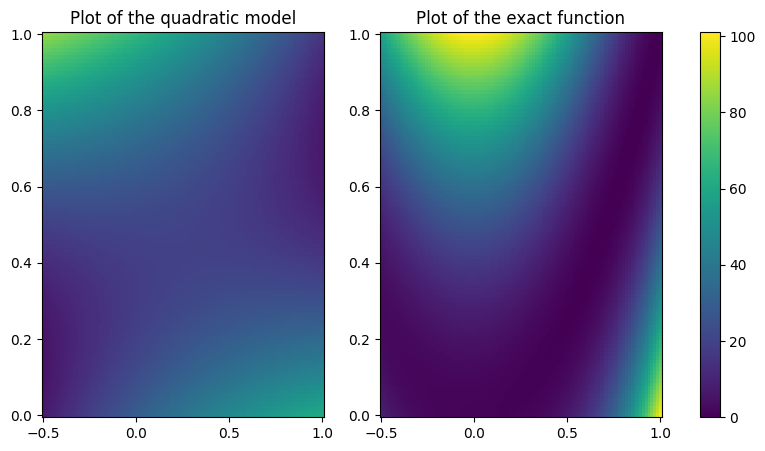

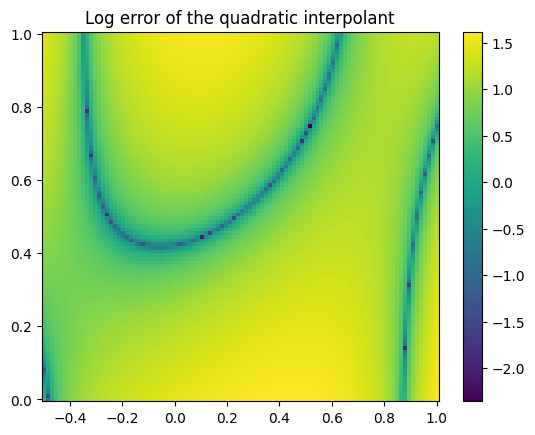

In [9]:
# Compute exact and model on a uniform grid
n_grid = 100
xx = np.linspace(lx, rx, n_grid)
yy = np.linspace(ly, ry, n_grid)
xx_grid, yy_grid = np.meshgrid(xx, yy)
grid = np.column_stack((xx_grid.ravel(), yy_grid.ravel()))
model_grid = quadratic_fit(grid).reshape(n_grid, n_grid)
exact_grid = rosenbrock(grid).reshape(n_grid, n_grid)

if d == 2:
    
    # Plot the model on a heatmap
    vmin = np.minimum(np.min(model_grid), np.min(exact_grid))
    vmax = np.maximum(np.max(model_grid), np.max(exact_grid))
    fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
    mesh1 = ax[0].pcolormesh(xx_grid, yy_grid, model_grid, cmap='viridis', vmin=vmin, vmax=vmax)
    ax[0].set_title('Plot of the quadratic model')

    # Plot the exact on a heatmap
    mesh2 = ax[1].pcolormesh(xx_grid, yy_grid, exact_grid, cmap='viridis', vmin=vmin, vmax=vmax)
    ax[1].set_title('Plot of the exact function')
    fig.colorbar(mesh1, ax=ax, location='right', aspect=20)

    # Plot the error on a heatmap
    error_grid = np.abs(model_grid - exact_grid)
    fig2, ax2 = plt.subplots()
    mesh3 = ax2.pcolormesh(xx_grid, yy_grid, np.log10(error_grid), cmap='viridis')
    fig2.colorbar(mesh3, location='right', aspect=20)
    ax2.set_title('Log error of the quadratic interpolant')

    plt.show()

### For research purposes: does using the Hessian of the least squares fit give a good clustering?
Note that, since we are using now quadratic fits, we cannot prove that Hessian clustering maximally reduces the error of the approximations after splitting.
However, it still comes for free with our interpolant (except for computing absolute value Hessians), and we saw from before that it is a good idea, so we should go along with it.

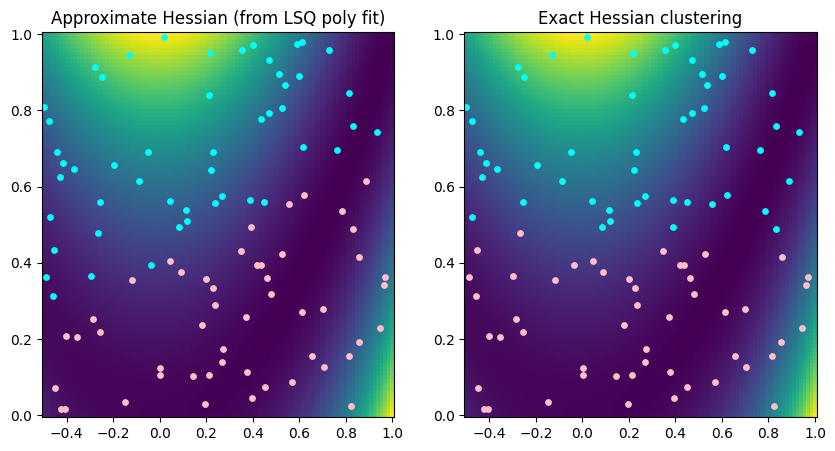

In [13]:
# H at mu should be the theoretical "best" Hessian.
# From least squares we compute an approximation to the Hessian.
H_approx = H

# Compute the absolute Hessian to use for clustering
# Then given this absolute Hessian, transform points and perform k-means (via PCA)
D, U = np.linalg.eigh(H_approx)
D_abs = np.maximum(np.abs(D), 1e-12)
D_abs_sqrt = np.sqrt(D_abs)
H_approx_sqrt_abs = (U * D_abs) @ U.T
x_transformed = x @ H_approx_sqrt_abs
U, _, _ = np.linalg.svd(x_transformed)
split_vec = U[:,0]
median = np.median(split_vec)
assign_vec = split_vec >= median

# Plot the clusters
if d == 2:
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].pcolormesh(xx_grid, yy_grid, exact_grid, cmap='viridis', vmin=vmin, vmax=vmax)
    ax[0].scatter(x[assign_vec == True][:,0], x[assign_vec == True][:,1], s=15, c='pink')
    ax[0].scatter(x[assign_vec == False][:,0], x[assign_vec == False][:,1], s=15, c='cyan')
    ax[0].set_title('Approximate Hessian (from LSQ poly fit)')

# Exact Hessian
H_exact = rosenbrock_hess(mu.reshape(1,2)).reshape(2,2)
D, U = np.linalg.eigh(H_exact)
D_abs = np.maximum(np.abs(D), 1e-12)
D_abs_sqrt = np.sqrt(D_abs)
H_exact_sqrt_abs = (U * D_abs) @ U.T
x_transformed = x @ H_exact_sqrt_abs
U, _, _ = np.linalg.svd(x_transformed)
split_vec = U[:,0]
median = np.median(split_vec)
assign_vec = split_vec >= median
if d == 2:
    ax[1].pcolormesh(xx_grid, yy_grid, exact_grid, cmap='viridis', vmin=vmin, vmax=vmax)
    ax[1].scatter(x[assign_vec == True][:,0], x[assign_vec == True][:,1], s=15, c='pink')
    ax[1].scatter(x[assign_vec == False][:,0], x[assign_vec == False][:,1], s=15, c='cyan')
    ax[1].set_title('Exact Hessian clustering')
    plt.show()
